In [2]:
cd /Users/cl1704/PycharmProjects/embedding_dimension/RNN

/Users/cl1704/PycharmProjects/embedding_dimension/RNN


In [7]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import seaborn as sns
from torch.utils.data import TensorDataset, DataLoader
plt.rcParams["axes.grid"] = False
import matplotlib
matplotlib.rcParams['axes.linewidth'] = .75


# Define RNN with low-rank connectivity
class MishaNet(torch.nn.Module):
    def __init__(self, n, alpha = .2, sigma_rec=0.15,sigma_in=0.2, input_size=2, output_size=2,dale=False,lambda_std=0.,base_in=0.,lambda_curve = 0,beta = 10, constrained=True ):
        super(MishaNet, self).__init__()
        self.alpha = torch.tensor(alpha)
        self.sigma_rec = torch.tensor(sigma_rec)
        self.sigma_in = torch.tensor(sigma_in)
        self.n = n
        self.input_size = input_size
        self.output_size = output_size
        self.dale = dale
        self.lambda_std = lambda_std
        self.base_in = base_in
        self.constrained  = constrained
        self.lambda_curve = lambda_curve
        self.beta = beta
        self.activation = torch.nn.Softplus(beta = self.beta)

        # Connectivity
        self.recurrent_layer_q = nn.Linear(self.n, 4, bias=False)
        self.recurrent_layer_q.requires_grad = True
        #self.recurrent_layer_q.bias.data.normal_(mean=0.05, std=0).to(device=device)

        #self.recurrent_layer.weight.data.fill_diagonal_(0)
        self.recurrent_layer_m = nn.Linear(4, self.n, bias=True)
        if self.constrained:
            self.recurrent_layer_m.requires_grad = False
        else:
            self.recurrent_layer_m.requires_grad = True
        # for i in range(self.n):
        #     self.recurrent_layer_m.weight.data[i,0] = torch.cos(torch.tensor(2*3.14*i/self.n)).float()
        #     self.recurrent_layer_m.weight.data[i,1] = torch.sin(torch.tensor(2*3.14*i/self.n)).float()

        self.input_layer = nn.Linear(self.input_size, self.n, bias=True)
        self.output_layer = nn.Linear(self.n, self.output_size, bias=True)

    # Dynamics
    def forward(self, u, training=False):
        t = u.shape[1]
        states = torch.zeros(u.shape[0], 1, self.n, device=device)

        batch_size = states.shape[0]
        input_noise = torch.sqrt(2 / self.alpha * self.sigma_in ** 2) * torch.empty(batch_size, t,
                                                                                    self.input_size).normal_(mean=0,
                                                                                                             std=1).to(
            device=device)

        inputs = self.input_layer(u + input_noise)
        # for i in range(t - 1):
        #     state_new = (1 - self.alpha) * states[:, i, :] + self.alpha * (
        #         self.activation(self.recurrent_layer_m(self.recurrent_layer_q(states[:, i, :])) + inputs[:, i, :]))
        #     states = torch.cat((states, state_new.unsqueeze_(1)), 1)

        for i in range(t - 1):
            state_new = (1 - self.alpha) * states[:, i, :] + self.alpha * (
                self.activation(self.recurrent_layer_m(self.recurrent_layer_q(states[:, i, :])) + inputs[:, i, :]))
            states = torch.cat((states, state_new.unsqueeze_(1)), 1)

        return states

    def linear_error(self,x,y):
        #y = self.linear_forward(u)
        x_centered = x - torch.mean(x, dim=[0, 1],keepdim=True)
        y_centered = y - torch.mean(y, dim=[0, 1],keepdim=True)
        numerator = torch.sum(x_centered * y_centered, dim=[0, 1])
        sigma_x = torch.sqrt(torch.sum(x_centered ** 2, dim=[0, 1]))
        sigma_y = torch.sqrt(torch.sum(y_centered ** 2, dim=[0, 1]))
        error = torch.mean(1 - (numerator / sigma_x / sigma_y) ** 2)
        return error


    def loss_function(self, u, x, z, lvar,dim):
        mse_z = nn.MSELoss()(x,z) / nn.MSELoss()(torch.zeros_like(z),z - torch.mean(z,dim=[0,1]))
        return mse_z + lvar * self.variance(x, dim) + \
                self.lambda_std * torch.std(torch.std(x, dim=[0, 1])) + \
                self.lambda_std * torch.std(torch.mean(x, dim=[0, 1]))              #self.lambda_curve

    def mse_z(self, x, z, mask):
        mse = nn.MSELoss()
        return mse(self.output_layer(x) * mask, z * mask)

    def variance(self, x, dim):
        # x = x[:, 14:, :]
        x = (x - torch.mean(x, dim=[0, 1])) #/ torch.std(x, dim=[0,1])
        eigs = torch.sort(torch.real(torch.linalg.eigvals(torch.cov(x.reshape(-1, x.shape[2]).t()))), descending=True)[
            0]
        return torch.sum(eigs[dim:]) / torch.sum(eigs)
    #    return eigs[dim]/ torch.sum(eigs) +.0001* (1 - eigs[dim-1])/ torch.sum(eigs)

    def fit(self, u, z, conditions, dim, lvar=0, lstd=0, epochs=10000, lr=.01, verbose=False, weight_decay=0):

        my_dataset = TensorDataset(u, z)  # create your datset
        my_dataloader = DataLoader(my_dataset, batch_size=64)

        if self.constrained:
            optimizer = torch.optim.Adam([self.recurrent_layer_q.weight,self.input_layer.weight,self.output_layer.weight,self.recurrent_layer_m.bias], lr=lr, weight_decay=weight_decay)
        else:
            optimizer = torch.optim.Adam([self.recurrent_layer_m.weight,self.recurrent_layer_q.weight,self.input_layer.weight,self.output_layer.weight,self.recurrent_layer_m.bias], lr=lr, weight_decay=weight_decay)
        epoch = 0
        # mse_z=1

        while epoch < epochs:
            # Fit LDS to all data at beginning of epoch

            #y = lds.output_layer(lds(u))
            for batch_idx, (u_batch, z_batch) in enumerate(my_dataloader):

                optimizer.zero_grad()
                x_batch = self.forward(u_batch, training=True)
                loss = self.loss_function(u_batch, x_batch, z_batch, lvar, dim)
                loss.backward()
                optimizer.step()

                epoch += 1
                if verbose:
                    if epoch % 50 == 0:
                        x = self.forward(u)
                        mse_z = nn.MSELoss()(x,z) / nn.MSELoss()(torch.zeros_like(z),z - torch.mean(z,dim=[0,1]))
                        print('Epoch: {}/{}.............'.format(epoch, epochs), end=' ')
                        print("mse_z: {:.4f}".format(mse_z.item()))

In [11]:
# Train Misha Net
from RNN.Experiment_4.ParametricWMTask import generate_trials
_, _, _, conditions = generate_trials(n_trials=25)
device = 'cpu'
u = torch.load('u_target.pth').detach().to(device)
z = torch.load('z_target.pth').detach().to(device)

net = MishaNet(n=100, input_size=u.shape[2],
          dale=False,
          sigma_in=0.,
          base_in=0,
          sigma_rec=0,
          lambda_std=0.,
          lambda_curve=0,
          beta=10).to(device)

net.fit(u.to(device=device),
            z.to(device=device),
            lr=.01,
            epochs=4000,
            conditions=conditions,
            verbose=True,
            lvar=0,
            dim=2,
            weight_decay=0)

Epoch: 50/4000............. mse_z: 1.9067
Epoch: 100/4000............. mse_z: 1.0184
Epoch: 150/4000............. mse_z: 0.8520
Epoch: 200/4000............. mse_z: 0.7721
Epoch: 250/4000............. mse_z: 0.7559
Epoch: 300/4000............. mse_z: 0.7404
Epoch: 350/4000............. mse_z: 0.7396
Epoch: 400/4000............. mse_z: 0.7442
Epoch: 450/4000............. mse_z: 0.7440
Epoch: 500/4000............. mse_z: 0.7387
Epoch: 550/4000............. mse_z: 0.7351
Epoch: 600/4000............. mse_z: 0.7357
Epoch: 650/4000............. mse_z: 0.7500
Epoch: 700/4000............. mse_z: 0.7370
Epoch: 750/4000............. mse_z: 0.7378
Epoch: 800/4000............. mse_z: 0.7367
Epoch: 850/4000............. mse_z: 0.7364
Epoch: 900/4000............. mse_z: 0.7471
Epoch: 950/4000............. mse_z: 0.7384
Epoch: 1000/4000............. mse_z: 0.7379
Epoch: 1050/4000............. mse_z: 0.7363
Epoch: 1100/4000............. mse_z: 0.7265
Epoch: 1150/4000............. mse_z: 0.7256
Epoch: 1

KeyboardInterrupt: 

Text(0.5, 1.0, 'b')

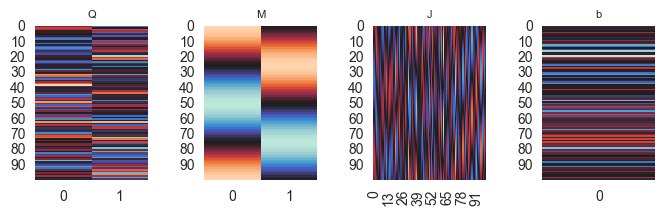

In [4]:
# Look at connectivity after training
fig = plt.figure(figsize=(8,2))
gs = gridspec.GridSpec(1,4,wspace = .5)

ax0=fig.add_subplot(gs[0,0])
sns.heatmap(net.recurrent_layer_q.weight.data.t().detach(), ax=ax0,cbar = False,center=0)
ax0.set_title("Q",fontsize=8)

ax1=fig.add_subplot(gs[0,1])
sns.heatmap(net.recurrent_layer_m.weight.data.detach(), ax=ax1,cbar = False,center=0)
ax1.set_title("M",fontsize=8)

ax2=fig.add_subplot(gs[0,2])
sns.heatmap(net.recurrent_layer_m.weight.data.detach()@net.recurrent_layer_q.weight.data.detach(), ax=ax2,cbar = False,center=0)
ax2.set_title("J",fontsize=8)

ax3=fig.add_subplot(gs[0,3])
sns.heatmap(net.recurrent_layer_m.bias.data.detach()[:,None],ax=ax3,cbar = False,center=0)
ax3.set_title("b",fontsize=8)

In [5]:
# Response matrix
# u, z, mask, conditions  = generate_trials(
#                             n_trials=50)
x = net(u).detach().cpu().numpy()
rows = []
for k in range(u.shape[0]):
    rows.append({'trial': k,
                 'theta': conditions[k]['theta'],
                 'response': x[k, :, :]})
df = pd.DataFrame(rows)
df = df.groupby(['theta']).response.apply(lambda r: np.mean(np.stack(r), axis=0)).reset_index()
responses = np.stack(df.response.values)
responses = responses.reshape(-1, responses.shape[2]).T

#responses = responses[np.mean(responses, axis=1) > .025, :]

responses = (responses - np.mean(responses, axis=1, keepdims=True)) / np.std(responses, axis=1, keepdims=True)
responses = responses[~np.isnan(responses).any(axis=1)]

0.1704304


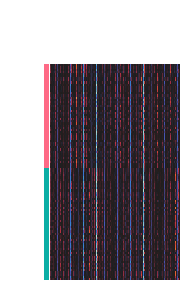

In [6]:
k = 2

import matplotlib
clustering = KMeans(n_clusters=k, n_init=20).fit(responses)
total_variance = np.sum((responses.T - np.mean(responses.T, axis=0, keepdims=True)) ** 2)
print(clustering.inertia_/total_variance)
labels = clustering.labels_
sort = np.argsort(labels)
sorted_responses = responses[sort, :]
sns.husl_palette(s=.4)
network_pal = sns.husl_palette(pd.Series(np.sort(labels)).unique().size, s=1)
lut = dict(zip(pd.Series(np.sort(labels)).unique(), network_pal))
row_colors = pd.Series(np.sort(labels)).map(lut)
g = sns.clustermap(pd.DataFrame((sorted_responses)), row_cluster=False, col_cluster=False, row_colors=row_colors,
                   figsize=(2,3), xticklabels=False, yticklabels=False,center=0,cbar_pos=None)
ax = g.ax_heatmap

g.savefig('/Users/cl1704/PycharmProjects/embedding_dimension/RNN/Figures/response_matrix.jpg',
          format='jpeg',
          dpi=450,
          bbox_inches='tight'
          )


(-31.593796825408937, 33.372584438323976)

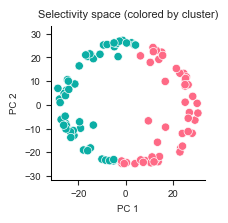

In [7]:
# Selectivity space (rates)
fig = plt.figure(figsize=(2,2))
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
x_proj = PCA().fit_transform(sorted_responses)
#sns.scatterplot(x = x_proj[:,0], y = x_proj[:,1],hue = np.mean(x, axis=(0,1)),legend=False)
sns.scatterplot(x = x_proj[:,0], y = x_proj[:,1],color  =row_colors,legend=False,ax=ax)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
# ax.spines['bottom'].set_visible(False)
# ax.spines['left'].set_visible(False)
ax.set_xlabel("PC 1", fontsize=7)
ax.set_ylabel("PC 2", fontsize=7)
ax.set_title("Selectivity space (colored by cluster)",fontsize=8)
ax.xaxis.set_tick_params(labelsize=7, bottom=True)
ax.yaxis.set_tick_params(labelsize=7, left=True)
ax.spines['left'].set_color('black')
ax.spines['bottom'].set_color('black')
lims = [
        np.min([ax.get_xlim(), ax.get_ylim()]),  # min of both axes
        np.max([ax.get_xlim(), ax.get_ylim()]),  # max of both axes
    ]

# now plot both limits against eachother
ax.set_aspect('equal')
ax.set_xlim(lims)
ax.set_ylim(lims)
# ax.axes.get_xaxis().set_visible(False)
# ax.axes.get_yaxis().set_visible(False)

Text(0, 0.5, 'Count')

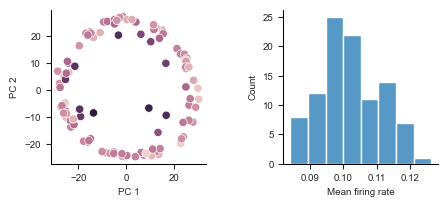

In [8]:
# Selectivity space, colored by mean rate
fig = plt.figure(figsize=(5,2))
gs = gridspec.GridSpec(1,2,wspace=0.5)
ax0=fig.add_subplot(gs[0,0])
ax1=fig.add_subplot(gs[0,1])
x_proj = PCA().fit_transform(responses)
sns.scatterplot(x = x_proj[:,0], y = x_proj[:,1],hue = np.mean(x, axis=(0,1)),legend=False,ax=ax0)
sns.histplot(x = np.std(x, axis=(0,1)),ax=ax1)
for ax in [ax0,ax1]:
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.xaxis.set_tick_params(labelsize=7, bottom=True)
    ax.yaxis.set_tick_params(labelsize=7, left=True)
    ax.spines['left'].set_color('black')
    ax.spines['bottom'].set_color('black')

ax0.set_xlabel("PC 1", fontsize=7)
ax0.set_ylabel("PC 2", fontsize=7)

ax1.set_xlabel("Mean firing rate", fontsize=7)
ax1.set_ylabel("Count", fontsize=7)


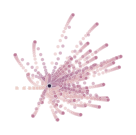

In [16]:
# STATE SPACE
net.sigma_rec = 0
net.sigma_in = 0
x = net.forward(u).detach().numpy()

n_components = 5
pca = PCA(n_components)
pca.fit(x.reshape(-1, x.shape[2]))
x_proj = pca.transform(x.reshape(-1, x.shape[2])).reshape(x.shape[0], x.shape[1], n_components)
rows = []
for k in range(u.shape[0]):
    for t in range(u.shape[1]):
        rows.append({'trial': k,
                     'theta': conditions[k]['theta'],
                     't': t,
                     'z_1': x_proj[k, t, 0],
                     'z_2': x_proj[k, t, 1], })
new_df = pd.DataFrame(rows)
new_df_mean = new_df.groupby(['theta', 't']).mean().reset_index()
fig = plt.figure(figsize=(1.5, 1.5))
gs = gridspec.GridSpec(1, 1)
ax = fig.add_subplot(gs[0, 0])

sns.scatterplot(data=new_df_mean, x='z_1', y='z_2', ax=ax, legend=False, s=6, alpha=.5, hue='t')

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.set_xlabel("PC 1", fontsize=7)
ax.set_ylabel("PC 2", fontsize=7)
#ax.set_title(r'$\sum_{i\geq 2}\lambda_i = $'+str(np.round(variance,4)),fontsize=8)
ax.xaxis.set_tick_params(labelsize=7, bottom=True)
ax.yaxis.set_tick_params(labelsize=7, left=True)
ax.spines['left'].set_color('black')
ax.spines['bottom'].set_color('black')
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
plt.gca().patch.set_alpha(0)


In [28]:
z = torch.tensor(z)
x = torch.tensor(x)
nn.MSELoss()(x,z) / nn.MSELoss()(torch.zeros_like(z),z - torch.mean(z,dim=[0,1]))

/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_2147/4135047052.py:1: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  z = torch.tensor(z)
/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_2147/4135047052.py:2: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  x = torch.tensor(x)


tensor(1.5514)

<Axes: ylabel='None'>

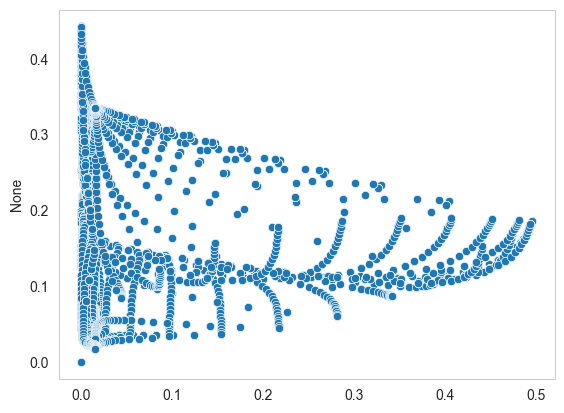

In [26]:
plt.figure()
sns.scatterplot(x=x[:,:,0].flatten(),y=z[:,:,0].flatten())

In [67]:
# synaptic input variable
u, z, mask, conditions  = generate_trials(
                            n_trials=50)
x = net(u)

x = (net.recurrent_layer_m(net.recurrent_layer_q(x)) + net.input_layer(u)).detach().numpy()

rows = []
for k in range(u.shape[0]):
    rows.append({'trial': k,
                 'motion': conditions[k]['motion_coh'],
                 'response': x[k, :, :]})
df = pd.DataFrame(rows)
df = df.groupby(['motion']).response.apply(lambda r: np.mean(np.stack(r), axis=0)).reset_index()

#df = df.groupby('motion').response.apply(lambda r: np.mean(np.stack(r), axis=0)).reset_index()
responses = np.stack(df.response.values)
responses = responses.reshape(-1, responses.shape[2]).T

#responses = responses[np.mean(responses, axis=1) > .025, :]

responses = (responses - np.mean(responses, axis=1, keepdims=True)) / np.std(responses, axis=1, keepdims=True)
responses = responses[~np.isnan(responses).any(axis=1)]

0.021248357


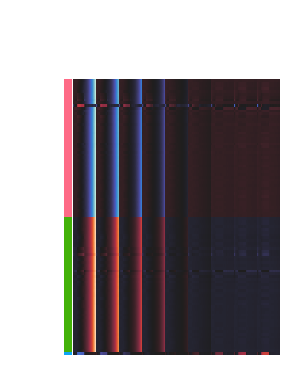

In [68]:
k = 3

import matplotlib
clustering = KMeans(n_clusters=k, n_init=20).fit(responses)
total_variance = np.sum((responses.T - np.mean(responses.T, axis=0, keepdims=True)) ** 2)
print(clustering.inertia_/total_variance)
labels = clustering.labels_
sort = np.argsort(labels)
sorted_responses = responses[sort, :]
sns.husl_palette(s=.4)
network_pal = sns.husl_palette(pd.Series(np.sort(labels)).unique().size, s=1)
lut = dict(zip(pd.Series(np.sort(labels)).unique(), network_pal))
row_colors = pd.Series(np.sort(labels)).map(lut)
g = sns.clustermap(pd.DataFrame((sorted_responses)), row_cluster=False, col_cluster=False, row_colors=row_colors,
                   figsize=(3, 3.75), xticklabels=False, yticklabels=False,center=0,cbar_pos=None)
ax = g.ax_heatmap

g.savefig('/Users/cl1704/PycharmProjects/embedding_dimension/RNN/Figures/response_matrix.jpg',
          format='jpeg',
          dpi=450,
          bbox_inches='tight'
          )


(-28.492095279693604, 28.623387622833253)

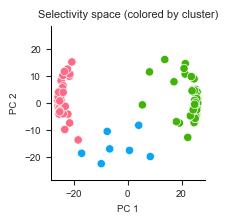

In [53]:
fig = plt.figure(figsize=(2,2))
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
x_proj = PCA().fit_transform(sorted_responses)
#sns.scatterplot(x = x_proj[:,0], y = x_proj[:,1],hue = np.mean(x, axis=(0,1)),legend=False)
sns.scatterplot(x = x_proj[:,0], y = x_proj[:,1],color  =row_colors,legend=False,ax=ax)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
# ax.spines['bottom'].set_visible(False)
# ax.spines['left'].set_visible(False)
ax.set_xlabel("PC 1", fontsize=7)
ax.set_ylabel("PC 2", fontsize=7)
ax.set_title("Selectivity space (colored by cluster)",fontsize=8)
ax.xaxis.set_tick_params(labelsize=7, bottom=True)
ax.yaxis.set_tick_params(labelsize=7, left=True)
ax.spines['left'].set_color('black')
ax.spines['bottom'].set_color('black')
lims = [
        np.min([ax.get_xlim(), ax.get_ylim()]),  # min of both axes
        np.max([ax.get_xlim(), ax.get_ylim()]),  # max of both axes
    ]

# now plot both limits against eachother
ax.set_aspect('equal')
ax.set_xlim(lims)
ax.set_ylim(lims)
# ax.axes.get_xaxis().set_visible(False)
# ax.axes.get_yaxis().set_visible(False)

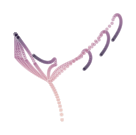

In [32]:
# STATE SPACE
#palette = sns.color_palette("coolwarm", n_colors=50,as_cmap=False)
palette = sns.husl_palette(75, s=1)

net.sigma_in = 0.
net.sigma_rec = 0
x = net.forward(u).detach().numpy()
#x = (x - np.mean(x, axis=(0, 1), keepdims=True)) / np.std(x, axis=(0, 1), keepdims=True)
#x = net(u)
n_components = 5
pca = PCA(n_components)
pca.fit(x.reshape(-1, x.shape[2]))
x_proj = pca.transform(x.reshape(-1, x.shape[2])).reshape(x.shape[0], x.shape[1], n_components)
rows = []
for k in range(u.shape[0]):
    for t in range(u.shape[1]):
        rows.append({'trial': k,
                     'motion': conditions[k]['motion_coh'],
                     'side': np.sign(conditions[k]['motion_coh']),
                     't': t,
                     'z_1': x_proj[k, t, 0],
                     'z_2': x_proj[k, t, 1], })
new_df = pd.DataFrame(rows)
new_df_mean = new_df.groupby(['motion', 't']).mean().reset_index()
fig = plt.figure(figsize=(1.5, 1.5))
gs = gridspec.GridSpec(1, 1)
ax = fig.add_subplot(gs[0, 0])

#sns.scatterplot(data=new_df,x='z_1',y='z_2',hue='t',ax=ax,legend=False,s=1,alpha=.1,edgecolor=None)

sns.scatterplot(data=new_df_mean, x='z_1', y='z_2', ax=ax, legend=False, s=6, alpha=.5, hue='t')
# sns.scatterplot(data=new_df_mean[new_df_mean.t==74],x='z_1',y='z_2',ax=ax,legend=False,s=6,alpha=1,hue='theta',palette=palette)

# Model predictions


ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.set_xlabel("PC 1", fontsize=7)
ax.set_ylabel("PC 2", fontsize=7)
#ax.set_title(r'$\sum_{i\geq 2}\lambda_i = $'+str(np.round(variance,4)),fontsize=8)
ax.xaxis.set_tick_params(labelsize=7, bottom=True)
ax.yaxis.set_tick_params(labelsize=7, left=True)
ax.spines['left'].set_color('black')
ax.spines['bottom'].set_color('black')
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
plt.gca().patch.set_alpha(0)
# ax.set_xlim(-1.25,1.25)
# ax.set_ylim(-1.25,1.25)
# matplotlib.rcParams['savefig.transparent'] = True
# fig.savefig('Figures/Figure_1_b.jpg',
#             format='jpeg',
#             dpi=450,
#             bbox_inches='tight', transparent=True)

<Axes: >

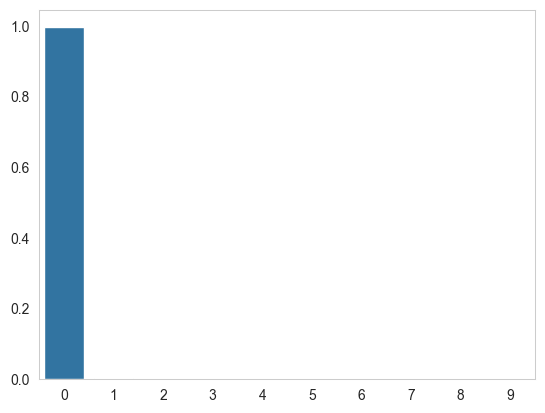

In [307]:
pca = PCA()
pca.fit(x.reshape(-1, x.shape[2]))
sns.barplot(x = np.arange(10),y=pca.explained_variance_ratio_[:10])

In [283]:
np.sum(pca.explained_variance_ratio_[2:])

np.float32(0.0015090535)

In [284]:
lds = LDS(n=2).to(device=device)
x = net.forward(u.to(device=device))
lds.fit(u.to(device=device), x.detach(), epochs=1000)
y = lds.output_layer(lds(u.to(device=device)))
linear_error = net.linear_error(x,y).detach().item()

0.6616523265838623
0.4569859206676483
0.34305495023727417
0.3210545480251312
0.3121228516101837
0.3060498535633087
0.29607728123664856
0.2846774756908417
0.2805320620536804
0.27903294563293457
0.2775299549102783
0.27548947930336
0.27571356296539307
0.2736140787601471
0.27291303873062134
0.27072787284851074
0.2715359926223755
0.2724621593952179
0.2745493948459625
0.27234774827957153
0.2715292274951935
0.2698996067047119
0.2633727788925171
0.2598784863948822
0.25925585627555847
0.2604479491710663
0.2572646737098694
0.2529135048389435
0.2513923943042755
0.25302353501319885
0.25145024061203003
0.2543106973171234
0.2537388503551483
0.25651609897613525
0.2549903392791748
0.2569962739944458
0.25538161396980286
0.2571840286254883
0.25536438822746277
0.25689801573753357
0.25456398725509644
0.26691555976867676
0.2648581266403198
0.26067012548446655
0.2585028409957886
0.26013532280921936
0.2585700750350952
0.26008617877960205
0.2586674094200134
0.2601205110549927
0.25877293944358826
0.26019024848

In [159]:
linear_error

0.22109122574329376

<Axes: >

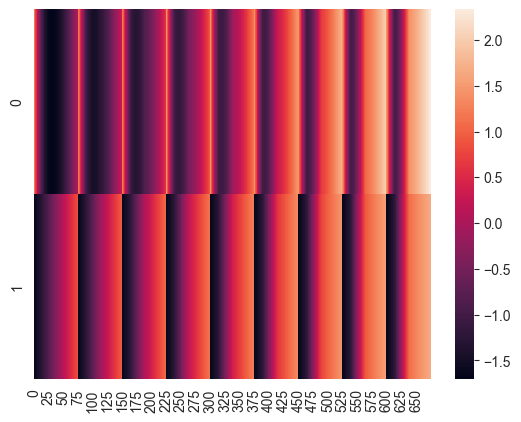

In [160]:
# Dynamics of linear system
u, z, mask, conditions  = generate_trials(
                            n_trials=50)
x = lds(u).detach().cpu().numpy()

rows = []
for k in range(u.shape[0]):
    rows.append({'trial': k,
                 'motion': conditions[k]['motion_coh'],
                 'response': x[k, :, :]})
df = pd.DataFrame(rows)
df = df.groupby(['motion']).response.apply(lambda r: np.mean(np.stack(r), axis=0)).reset_index()

#df = df.groupby('motion').response.apply(lambda r: np.mean(np.stack(r), axis=0)).reset_index()
responses = np.stack(df.response.values)
responses = responses.reshape(-1, responses.shape[2]).T

#responses = responses[np.mean(responses, axis=1) > .025, :]

responses = (responses - np.mean(responses, axis=1, keepdims=True)) / np.std(responses, axis=1, keepdims=True)
responses = responses[~np.isnan(responses).any(axis=1)]

plt.figure()
sns.heatmap(responses)

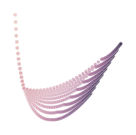

In [161]:
# STATE SPACE
#palette = sns.color_palette("coolwarm", n_colors=50,as_cmap=False)
palette = sns.husl_palette(75, s=1)

net.sigma_in = 0.
net.sigma_rec = 0
x = lds.forward(u).detach().numpy()
#x = (x - np.mean(x, axis=(0, 1), keepdims=True)) / np.std(x, axis=(0, 1), keepdims=True)
#x = net(u)
n_components = 2
pca = PCA(n_components = n_components)
pca.fit(x.reshape(-1, x.shape[2]))
x_proj = pca.transform(x.reshape(-1, x.shape[2])).reshape(x.shape[0], x.shape[1], n_components)
rows = []
for k in range(u.shape[0]):
    for t in range(u.shape[1]):
        rows.append({'trial': k,
                     'motion': conditions[k]['motion_coh'],
                     'side': np.sign(conditions[k]['motion_coh']),
                     't': t,
                     'z_1': x_proj[k, t, 0],
                     'z_2': x_proj[k, t, 1], })
new_df = pd.DataFrame(rows)
new_df_mean = new_df.groupby(['motion', 't']).mean().reset_index()
fig = plt.figure(figsize=(1.5, 1.5))
gs = gridspec.GridSpec(1, 1)
ax = fig.add_subplot(gs[0, 0])

#sns.scatterplot(data=new_df,x='z_1',y='z_2',hue='t',ax=ax,legend=False,s=1,alpha=.1,edgecolor=None)

sns.scatterplot(data=new_df_mean, x='z_1', y='z_2', ax=ax, legend=False, s=6, alpha=.5, hue='t')
# sns.scatterplot(data=new_df_mean[new_df_mean.t==74],x='z_1',y='z_2',ax=ax,legend=False,s=6,alpha=1,hue='theta',palette=palette)

# Model predictions


ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.set_xlabel("PC 1", fontsize=7)
ax.set_ylabel("PC 2", fontsize=7)
#ax.set_title(r'$\sum_{i\geq 2}\lambda_i = $'+str(np.round(variance,4)),fontsize=8)
ax.xaxis.set_tick_params(labelsize=7, bottom=True)
ax.yaxis.set_tick_params(labelsize=7, left=True)
ax.spines['left'].set_color('black')
ax.spines['bottom'].set_color('black')
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
plt.gca().patch.set_alpha(0)
# ax.set_xlim(-1.25,1.25)
# ax.set_ylim(-1.25,1.25)
# matplotlib.rcParams['savefig.transparent'] = True
# fig.savefig('Figures/Figure_1_b.jpg',
#             format='jpeg',
#             dpi=450,
#             bbox_inches='tight', transparent=True)

In [127]:
x.shape

(450, 75, 2)

In [ ]:
class LDS(torch.nn.Module):
    def __init__(self, n, alpha=.2, input_size=2, output_size=50):
        super(LDS, self).__init__()
        self.alpha = torch.tensor(alpha)
        self.n = n
        self.observation_size = 50
        self.input_size = input_size
        self.output_size = output_size

        # Connectivity
        self.recurrent_layer = nn.Linear(self.n, self.n, bias=True)
        self.input_layer = nn.Linear(self.input_size, self.n, bias=True)
        self.output_layer = nn.Linear(self.n, self.output_size, bias=True)



    # Dynamics
    def forward(self, u, training=False):
        t = u.shape[1]
        states = torch.zeros(u.shape[0], 1, self.n, device=device)

        inputs = self.input_layer(u)
        for i in range(t - 1):
            state_new = (1 - self.alpha) * states[:, i, :] + self.alpha * (
                self.recurrent_layer(states[:, i, :]) + inputs[:, i, :])
            states = torch.cat((states, state_new.unsqueeze_(1)), 1)

        return states


    def loss_function(self, u, y):

        x = self.output_layer(self.forward(u))
        x_centered = x - torch.mean(x, dim=[0, 1], keepdim=True)
        y_centered = y - torch.mean(y, dim=[0, 1], keepdim=True)

        numerator = torch.sum(x_centered * y_centered, dim=[0, 1])

        sigma_x = torch.sqrt(torch.sum(x_centered ** 2, dim=[0, 1]))
        sigma_y = torch.sqrt(torch.sum(y_centered ** 2, dim=[0, 1]))

        error = torch.mean(1 - (numerator / sigma_x / sigma_y) ** 2)

        return error

    def fit(self, u, y, epochs=5, lr=.005, weight_decay=0):

        my_dataset = TensorDataset(u, y)  # create your datset
        my_dataloader = DataLoader(my_dataset, batch_size=32)

        optimizer = torch.optim.Adam(self.parameters(), lr=lr, weight_decay=weight_decay)
        epoch = 0
        while epoch < epochs:

            for batch_idx, (u_batch, y_batch) in enumerate(my_dataloader):
                optimizer.zero_grad()
                loss = self.loss_function(u_batch, y_batch)
                loss.backward()
                optimizer.step()
                epoch += 1
            print(loss.item())


In [4]:
import os
df_list = []
for filename in os.listdir('Experiment_4/Results_4'):
    f = os.path.join('Experiment_4/Results_4', filename)
    if os.path.isfile(f):
        df_list.append(pd.read_pickle(f))
original_df = pd.concat(df_list,ignore_index=True)
#original_df = original_df[original_df.mse_z<.001]

# original_df = original_df[(original_df.linear_error>0.05) & (original_df.linear_error<.07)]
#original_df = original_df[original_df.snr<.1]
original_df = original_df[original_df.n==100]
original_df = original_df[original_df.pca_error<.1]
original_df = original_df[original_df.linear_error>.8]
#original_df = original_df[original_df.pca_error<.01]
original_df.sort_values('pca_error',ascending=True)#

,model_id,w_rec,w_in,w_out,bias,mse_z,epochs,sigma_rec,sigma_in,weight_decay,...,lambda_pca_1,lambda_pca_2,lambda_linear,n,lvar,dim,null_kmeans_error,pca_error,kmeans_error,linear_error
32501,2yVgKpUd,"[[0.0, 0.018748723, -0.04817973, -0.07847197, ...","[[0.20299204, -0.039746907], [0.04077565, -0.0...","[[0.08966577, 0.05898874, 0.08641257, 0.033777...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",1.124305,1000,0.0,0.0,0.002,...,1.0,1.0,1.0,100,2.0,4,0.093184,0.002353,0.028444,0.899750
22886,fMm5CBAl,"[[0.0, -0.04882038, -0.0006502714, -0.07166557...","[[-0.060710046, -0.11861296], [-0.17510681, 0....","[[-0.009712112, -0.008192527, -0.001750958, 0....","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",1.103693,1000,0.0,0.0,0.002,...,1.0,1.0,1.0,100,2.0,4,0.086092,0.002794,0.026778,0.822340
32515,t5Ip2YxU,"[[0.0, -0.09066048, -0.046863273, -0.017990671...","[[0.20731217, 0.12380663], [-0.16723269, 0.089...","[[0.09535449, -0.03749291, -0.015980853, -0.01...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",1.095125,1000,0.0,0.0,0.002,...,1.0,1.0,1.0,100,2.0,4,0.113330,0.002850,0.018831,0.837958
16737,sx1V4vSM,"[[0.0, -0.03563201, -0.04496676, -0.051608395,...","[[-0.063909374, 0.23628594], [0.32049885, -0.2...","[[0.051033344, -0.07223417, -0.032950234, -0.0...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",1.427716,1000,0.0,0.0,0.002,...,1.0,1.0,1.0,100,2.0,4,0.103310,0.002911,0.047121,0.861355
22902,eTBEKtkx,"[[0.0, -0.051844336, 0.010811702, -0.16590536,...","[[0.0026506262, -0.010980488], [-0.22563182, -...","[[-0.08565179, -0.043905415, 0.08720865, -0.02...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",1.066184,1000,0.0,0.0,0.002,...,1.0,1.0,1.0,100,2.0,4,0.077728,0.003038,0.029505,0.883140
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15296,jMeYbgtN,"[[0.0, 0.052686036, -0.036478586, -0.048472505...","[[0.17048326, -0.090138435], [0.020950321, -0....","[[0.0068430067, 0.016879428, -0.030495787, 0.0...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",1.226899,1000,0.0,0.0,0.002,...,1.0,1.0,1.0,100,2.0,4,0.360569,0.099543,0.332564,0.849945
26276,5013NhaQ,"[[0.0, -0.05061028, -0.058069903, 0.18673965, ...","[[0.22377588, 0.30851072], [-0.008399417, -0.0...","[[-0.08832083, 0.02384988, -0.06856506, 0.0694...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",1.067833,1000,0.0,0.0,0.002,...,1.0,1.0,1.0,100,2.0,4,0.354879,0.099699,0.346868,0.891849
36895,iUj2ngY9,"[[0.0, -0.02213541, -0.027499856, -0.043591734...","[[0.116499424, 0.0959594], [-0.30437323, 0.031...","[[0.09035363, 0.09369232, 0.096163265, 0.06563...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",1.045339,1000,0.0,0.0,0.002,...,1.0,1.0,1.0,100,2.0,4,0.387224,0.099739,0.381306,0.810098
32291,gv0ajT0J,"[[0.0, 0.054017626, 0.031090373, -0.118170835,...","[[0.26864934, 0.072148085], [-0.08377548, -0.0...","[[-0.06552793, 0.015375495, 0.0443764, -0.0428...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",1.109660,1000,0.0,0.0,0.002,...,1.0,1.0,1.0,100,2.0,4,0.339160,0.099805,0.328418,0.861772


In [ ]:
from RNN.Experiment_4.net import *
from RNN.Experiment_4.ParametricWMTask import generate_trials
u, _, _, conditions = generate_trials(n_trials=25)
device = 'cpu'
constrained_scores = []
unconstrained_scores = []
for i in range(1000):
    model_data = original_df.iloc[i,:]
    net = Net(n=100,input_size = 2,dale=False)
    net.recurrent_layer.weight.data = torch.tensor(model_data['w_rec'])
    net.recurrent_layer.bias.data = torch.tensor(model_data['bias'])
    net.input_layer.weight.data = torch.tensor(model_data['w_in'])
    net.input_layer.bias.data = torch.tensor(0.2)
    net.output_layer.weight.data = torch.tensor(model_data['w_out'])
    net.output_layer.bias.data = torch.tensor(-0.2)
    net.sigma_in = 0.0
    net.sigma_rec = 0.0
    net
    z = net.forward(u).detach()

    mishanet = MishaNet(n=100, input_size=u.shape[2],
          dale=False,
          sigma_in=0.,
          base_in=0,
          sigma_rec=0,
          lambda_std=0.,
          lambda_curve=0,
          beta=10,
          constrained=True)

    mishanet.fit(u,
                z,
                lr=.01,
                epochs=1000,
                conditions=conditions,
                verbose=True,
                lvar=0,
                dim=2,
                weight_decay=0)


    x = mishanet.forward(u)
    mse_z = nn.MSELoss()(x,z) / nn.MSELoss()(torch.zeros_like(z),z - torch.mean(z,dim=[0,1]))
    constrained_scores.append(mse_z)

    mishanet = MishaNet(n=100, input_size=u.shape[2],
          dale=False,
          sigma_in=0.,
          base_in=0,
          sigma_rec=0,
          lambda_std=0.,
          lambda_curve=0,
          beta=10,
          constrained=False).to(device)

    mishanet.fit(u.to(device=device),
                z.to(device=device),
                lr=.01,
                epochs=1000,
                conditions=conditions,
                verbose=True,
                lvar=0,
                dim=2,
                weight_decay=0)

    z = net.forward(u)
    x = mishanet.forward(u)
    mse_z = nn.MSELoss()(x,z) / nn.MSELoss()(torch.zeros_like(z),z - torch.mean(z,dim=[0,1]))
    unconstrained_scores.append(mse_z)



Epoch: 50/1000............. mse_z: 1.5698
Epoch: 100/1000............. mse_z: 1.0013
Epoch: 150/1000............. mse_z: 0.8509
Epoch: 200/1000............. mse_z: 0.8191
Epoch: 250/1000............. mse_z: 0.7773
Epoch: 300/1000............. mse_z: 0.7677
Epoch: 350/1000............. mse_z: 0.7662
Epoch: 400/1000............. mse_z: 0.7630
Epoch: 450/1000............. mse_z: 0.7651
Epoch: 500/1000............. mse_z: 0.7622
Epoch: 550/1000............. mse_z: 0.7517
Epoch: 600/1000............. mse_z: 0.7799
Epoch: 650/1000............. mse_z: 0.7608
Epoch: 700/1000............. mse_z: 0.7595
Epoch: 750/1000............. mse_z: 0.7584
Epoch: 800/1000............. mse_z: 0.7578
Epoch: 850/1000............. mse_z: 0.7463
Epoch: 900/1000............. mse_z: 0.7457
Epoch: 950/1000............. mse_z: 0.7454
Epoch: 1000/1000............. mse_z: 0.7455
Epoch: 50/1000............. mse_z: 1.2751
Epoch: 100/1000............. mse_z: 0.8363
Epoch: 150/1000............. mse_z: 0.3775
Epoch: 200/1

<Axes: ylabel='Count'>

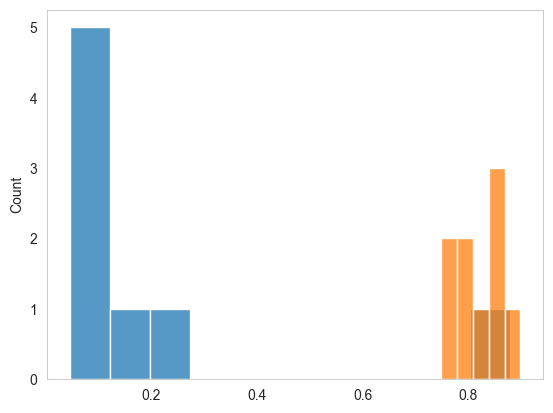

In [17]:
plt.figure()
sns.histplot(x = [x.item() for x in unconstrained_scores])
sns.histplot(x = [x.item() for x in constrained_scores])

In [ ]:
model_data = original_df[original_df.model_id=='iU14Tb5q']
net = Net(n=100,input_size = 2,dale=False)
net.recurrent_layer.weight.data = torch.tensor(model_data['w_rec'].item())
net.recurrent_layer.bias.data = torch.tensor(model_data['bias'].item())
net.input_layer.weight.data = torch.tensor(model_data['w_in'].item())
net.input_layer.bias.data = torch.tensor(0.2)
net.output_layer.weight.data = torch.tensor(model_data['w_out'].item())
net.output_layer.bias.data = torch.tensor(-0.2)
net.sigma_in = 0.0

In [75]:
import os
df_list = []
for filename in os.listdir('Experiment_7/Results_7'):
    f = os.path.join('Experiment_7/Results_7', filename)
    if os.path.isfile(f):
        df_list.append(pd.read_pickle(f))
original_df = pd.concat(df_list,ignore_index=True)
#original_df = original_df[original_df.mse_z<.001]

# original_df = original_df[(original_df.linear_error>0.05) & (original_df.linear_error<.07)]
original_df = original_df[original_df.snr<.1]
original_df = original_df[original_df.n==100]
#original_df = original_df[original_df.kmeans_error<.1]
original_df = original_df[original_df.linear_error>.75]
original_df = original_df[original_df.pca_error<.1]
original_df.sort_values('pca_error',ascending=True)#

,model_id,w_rec,w_in,w_out,bias,mse_z,epochs,sigma_rec,sigma_in,weight_decay,...,lambda_pca_1,lambda_pca_2,lambda_linear,n,lvar,dim,null_kmeans_error,pca_error,kmeans_error,linear_error
25877,wF8pjxt4,"[[0.0, -0.034981348, -0.03227675, -0.02357753,...","[[0.14764446, -0.07062929], [-0.12617658, 0.09...","[[-0.07098194, -0.016648078, -0.08040166, 0.07...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",1.099786,1000,0.0,0.0,0.002,...,1.0,1.0,1.0,100,2.0,2,0.127211,0.028372,0.082538,0.916805
25936,owPXG5Nv,"[[0.0, -0.013260287, -0.009954059, -0.00960659...","[[0.06904386, 0.031272814], [-0.06607267, 0.01...","[[-0.05218463, 0.03314376, -0.064921044, -0.00...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",1.264025,1000,0.0,0.0,0.002,...,1.0,1.0,1.0,100,2.0,2,0.167793,0.030510,0.103767,2.967039
16513,kSIDQldo,"[[0.0, 0.013435261, -0.018987605, -0.035240863...","[[-0.040663525, -0.051936902], [-0.01850253, 0...","[[0.010651648, 0.035437286, 0.05468098, 0.0259...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",1.160524,1000,0.0,0.0,0.002,...,1.0,1.0,1.0,100,2.0,2,0.142987,0.034239,0.053343,0.919677
24779,FvSH0i6d,"[[0.0, 0.0037940964, -0.03362337, -0.038764417...","[[0.006262483, 0.014217199], [0.05339999, 0.08...","[[0.036581933, -0.060475577, 0.029214228, 0.08...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",1.132384,1000,0.0,0.0,0.002,...,1.0,1.0,1.0,100,2.0,2,0.173703,0.044639,0.071715,0.937399
21328,owMfpifp,"[[0.0, -0.088625856, -0.028544834, -0.01925671...","[[-0.023318253, -0.03239486], [-0.011740318, -...","[[0.020366669, -0.01624061, -0.025210155, 0.04...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",1.094531,1000,0.0,0.0,0.002,...,1.0,1.0,1.0,100,2.0,2,0.127691,0.048645,0.079109,0.936856
9988,OW1aVpgF,"[[0.0, -0.065764755, -0.08037004, 0.022022063,...","[[0.04470519, -0.022785727], [-0.009773381, 0....","[[0.085380904, 0.07678717, -0.036673225, 0.091...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",1.155115,1000,0.0,0.0,0.002,...,1.0,1.0,1.0,100,2.0,2,0.114387,0.049135,0.076283,0.938221
8234,JLzXmv1O,"[[0.0, 0.038504995, 0.019563198, -0.038939714,...","[[0.03916093, 0.00909588], [0.0051368577, -0.0...","[[0.07320531, -0.048456516, -0.08018501, -0.03...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",1.122229,1000,0.0,0.0,0.002,...,1.0,1.0,1.0,100,2.0,2,0.135628,0.051132,0.080396,0.942968
14474,XWsS0WQG,"[[0.0, 0.004492901, 0.012176793, -0.049269628,...","[[0.119449444, -0.0058208173], [-0.04323207, 0...","[[0.054811656, -0.033040788, -0.07515538, 0.02...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",1.056440,1000,0.0,0.0,0.002,...,1.0,1.0,1.0,100,2.0,2,0.160110,0.056215,0.107885,0.945903
24643,LKdj4P3f,"[[0.0, -0.003256417, -0.031450283, 0.007761867...","[[-0.02959546, -0.23744896], [0.21856734, 0.36...","[[0.01148696, 0.0032428503, -0.008657289, 0.01...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",1.219162,1000,0.0,0.0,0.002,...,1.0,1.0,1.0,100,2.0,2,0.154390,0.061523,0.129921,0.916684
17220,ovBxBQPu,"[[0.0, -0.04554935, 0.0072798277, 0.013708622,...","[[-0.09316341, 0.011652528], [0.06495365, -0.0...","[[-0.039992977, 0.06477771, -0.08129276, 0.059...","[0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2, ...",1.281188,1000,0.0,0.0,0.002,...,1.0,1.0,1.0,100,2.0,2,0.461925,0.062903,0.452052,0.853785


In [83]:
# "BezRVITu", "SdkzAQtT","i2MHGwgp",
from Experiment_4.net import *
model_data = original_df[original_df.model_id=='kSIDQldo']
net = Net(n=100,input_size = 2,dale=False)
net.recurrent_layer.weight.data = torch.tensor(model_data['w_rec'].item())
net.recurrent_layer.bias.data = torch.tensor(model_data['bias'].item())
net.input_layer.weight.data = torch.tensor(model_data['w_in'].item())
net.input_layer.bias.data = torch.tensor(0.2)
net.output_layer.weight.data = torch.tensor(model_data['w_out'].item())
net.output_layer.bias.data = torch.tensor(-0.2)
net.sigma_in = 0.0
from Experiment_4.ParametricWMTask import generate_trials
u, z, mask, conditions  = generate_trials(
                            n_trials=25)

z = net.forward(u).detach()


In [84]:
mishanet = MishaNet(n=100, input_size=u.shape[2],
          dale=False,
          sigma_in=0.,
          base_in=0,
          sigma_rec=0,
          lambda_std=0.,
          lambda_curve=0,
               constrained=True,
          beta=10).to(device)

mishanet.fit(u.to(device=device),
            z.to(device=device),
            lr=.001,
            epochs=4000,
            conditions=conditions,
            verbose=True,
            lvar=0,
            dim=2,
            weight_decay=0)

Epoch: 50/4000............. mse_z: 5.0476
Epoch: 100/4000............. mse_z: 4.3801
Epoch: 150/4000............. mse_z: 3.8199
Epoch: 200/4000............. mse_z: 3.3399
Epoch: 250/4000............. mse_z: 2.9280
Epoch: 300/4000............. mse_z: 2.5713
Epoch: 350/4000............. mse_z: 2.2714
Epoch: 400/4000............. mse_z: 2.0271
Epoch: 450/4000............. mse_z: 1.8213
Epoch: 500/4000............. mse_z: 1.6388
Epoch: 550/4000............. mse_z: 1.4993
Epoch: 600/4000............. mse_z: 1.3817
Epoch: 650/4000............. mse_z: 1.2868
Epoch: 700/4000............. mse_z: 1.2113
Epoch: 750/4000............. mse_z: 1.1526
Epoch: 800/4000............. mse_z: 1.1040
Epoch: 850/4000............. mse_z: 1.0653
Epoch: 900/4000............. mse_z: 1.0322
Epoch: 950/4000............. mse_z: 1.0065
Epoch: 1000/4000............. mse_z: 0.9835
Epoch: 1050/4000............. mse_z: 0.9629
Epoch: 1100/4000............. mse_z: 0.9440
Epoch: 1150/4000............. mse_z: 0.9314
Epoch: 1

In [85]:
# Get trajectories

from Experiment_4.ParametricWMTask import generate_trials
u, z, mask, conditions  = generate_trials(
                            n_trials=1,n_conditions = 2000)
palette = sns.husl_palette(s=1,n_colors=2000)

mishanet.sigma_in = 0.
mishanet.sigma_rec = 0
#x = lds.output_layer(lds.forward(u))
x = mishanet.forward(u)
#x = x-torch.mean(x,dim=[0,1],keepdim=True)
x = x.detach().cpu().numpy()[:,7:,:]
n_neurons = x.shape[2]

pca = PCA(n_components=2).fit(x.reshape(-1, x.shape[2]))
x_proj = pca.transform(x.reshape(-1, x.shape[2])).reshape(x.shape[0], x.shape[1], 2)
rows = []
for k in range(x.shape[0]):
    for t in range(x.shape[1]):
        rows.append({'trial': k,
                     'theta': conditions[k]['theta'],
                     't': t,
                     'z_1': x_proj[k, t, 0],
                     'z_2': x_proj[k, t, 1], })
new_df = pd.DataFrame(rows)
new_df_mean = new_df.groupby(['theta', 't']).mean().reset_index()

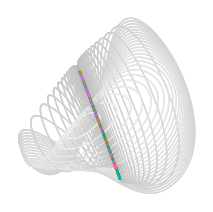

In [93]:


fig = plt.figure(figsize=(2.5,2.5))
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])



#
sns.scatterplot(data=new_df, x='z_1', y='z_2', ax=ax, legend=False, s=1,hue = 't', alpha=.5,palette =sns.light_palette("gray",as_cmap=True))

#sns.scatterplot(data=new_df, x='z_1', y='z_2', ax=ax, legend=False, s=4, alpha=1)
sns.scatterplot(data=new_df[new_df.t==55],x='z_1',y='z_2',hue='theta',ax=ax,legend=False,s=2,alpha=1,palette = palette,edgecolor=None)

# sns.scatterplot(data=new_df[new_df.t==15],x='z_1',y='z_2',hue='theta',ax=ax,legend=False,s=2,alpha=1,palette = palette,edgecolor=None)
#
# sns.scatterplot(data=new_df[new_df.t==30],x='z_1',y='z_2',hue='theta',ax=ax,legend=False,s=2,alpha=1,palette = palette,edgecolor=None)
#
# sns.scatterplot(data=new_df[new_df.t>70],x='z_1',y='z_2',hue='theta',ax=ax,legend=False,s=.25,alpha=.25,palette = palette,edgecolor=None)
# lims = [
#         1*np.min([ax.get_xlim(), ax.get_ylim()]),  # min of both axes
#         1*np.max([ax.get_xlim(), ax.get_ylim()]),  # max of both axes
#     ]
# ax.set_aspect('equal')
# ax.set_xlim(lims)
# ax.set_ylim(lims)

# Plot restriction of hyperplanes to subspace

# Get first two principal components
# U = pca.components_.T
#
# # Get connectiivity
# w = net.recurrent_layer.weight.data
# b = net.recurrent_layer.bias.data
#
#
# # Restrict recurrent connectivity to subspace defined by U.
# H = w @ U
# shift = b
# #shift = 0
#
# # # Hyperplanes
# lim =3
# xx,yy = np.linspace(lims[0],lims[1]), np.linspace(lims[0],lims[1])
# x,y = np.meshgrid(xx,yy)
# for i in range(n_neurons):
#     ax.contour(x, y, x*H[i,0].numpy() + y*H[i,1].numpy()+shift[i].numpy(), [0],colors='gray',linewidths=.75,alpha=.5)


ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.set_xlabel("PC 1", fontsize=7)
ax.set_ylabel("PC 2", fontsize=7)
ax.xaxis.set_tick_params(labelsize=7, bottom=False)
ax.yaxis.set_tick_params(labelsize=7, left=False)
ax.spines['left'].set_color('black')
ax.spines['bottom'].set_color('black')
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)

plt.savefig('Figures/Fig1c.jpg',
    format='jpeg',
    transparent=True,
    dpi=450,
            bbox_inches='tight'
)

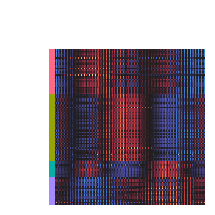

In [94]:
## RESPONSE MATRIX
from Experiment_4.ParametricWMTask import generate_trials

# Response matrix
rows = []
for k in range(u.shape[0]):
    rows.append({'trial': k,
                 'theta': conditions[k]['theta'],
                 'response': x[k, :, :]})
df = pd.DataFrame(rows)
df = df.groupby(['theta']).response.apply(lambda r: np.mean(np.stack(r), axis=0)).reset_index()
responses = np.stack(df.response.values)
responses = responses.reshape(-1, responses.shape[2]).T


# z_score
responses = (responses - np.mean(responses, axis=1, keepdims=True)) / np.std(responses, axis=1, keepdims=True)
responses = responses[~np.isnan(responses).any(axis=1)]



## CLUSTERED RESPONSE MATRIX
#_,k = compute_k(responses,5,25,.05)
k = 4

clustering = KMeans(n_clusters=k,n_init=20).fit(responses)
labels  = clustering.labels_
sort = np.argsort(labels)
sorted_responses = responses[sort,:]
sns.husl_palette(s=.4)
network_pal = sns.husl_palette(pd.Series(np.sort(labels)).unique().size,s=1)
lut = dict(zip(pd.Series(np.sort(labels)).unique(),network_pal))
row_colors = pd.Series(np.sort(labels)).map(lut)
g = sns.clustermap(pd.DataFrame((sorted_responses)),row_cluster=False, col_cluster=False, row_colors=row_colors,figsize=(2.25,2.25),cbar_pos=None, xticklabels=False, yticklabels=False,center=0)
ax = g.ax_heatmap

g.savefig('Figures/Fig_2afc_b.jpg',
    format='jpeg',
    dpi=450,
            bbox_inches='tight'
)

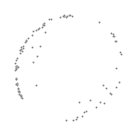

In [95]:
## LDA

pca = PCA()
pca.fit(responses, labels)
x_proj = pca.transform(responses)
x_proj = x_proj + 3*(2*np.random.rand(x_proj.shape[0],x_proj.shape[1])-1)

lut = dict(zip(pd.Series(np.sort(labels)).unique(),network_pal))
row_colors = pd.Series(np.sort(labels)).map(lut)

fig = plt.figure(figsize=(1.5,1.5))
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
# sns.scatterplot(x=x_proj[np.argsort(labels), 0], y=x_proj[np.argsort(labels), 1], color=row_colors,s=6,alpha=1,ax=ax)
sns.scatterplot(x=x_proj[np.argsort(labels), 0], y=x_proj[np.argsort(labels), 1], color='gray',s=2,alpha=1,ax=ax)
centers_proj = pca.transform(clustering.cluster_centers_)

#sns.scatterplot(x=centers_proj[:, 0], y=centers_proj[:, 1], color='k',s=3,alpha=1,ax=ax,edgecolor=None)

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.xaxis.set_tick_params(labelsize=8,bottom=True)
ax.yaxis.set_tick_params(labelsize=8,left=True)
ax.spines['left'].set_color('black')
ax.spines['bottom'].set_color('black')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
# ax.set_xlim(-30,30)
# ax.set_ylim(-30,30)
plt.savefig('Figures/Fig1c.jpg',
    format='jpeg',
    dpi=450,
            bbox_inches='tight'
)

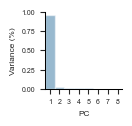

In [67]:
## PCA
fig = plt.figure(figsize=(1,1))
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
pca = PCA().fit(responses.T)
sns.barplot(x = np.arange(1,9),y=pca.explained_variance_ratio_[:8],alpha=.5,ax=ax,width=1)
ax.set_xlabel("PC", fontsize=6)
ax.set_ylabel("Variance (%)", fontsize=6)
#ax.set_title(r'$\sum_{i\geq 2}\lambda_i = $'+str(np.round(variance,4)),fontsize=8)
ax.xaxis.set_tick_params(labelsize=5, bottom=True)
ax.yaxis.set_tick_params(labelsize=5, left=True)
ax.spines['left'].set_color('black')
ax.spines['bottom'].set_color('black')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.savefig('Figures/Fig1c.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight'
            )

In [103]:
df_list = []
for filename in os.listdir('Experiment_8/Results_8'):
    f = os.path.join('Experiment_8/Results_8', filename)
    if os.path.isfile(f):
        df_list.append(pd.read_pickle(f))
df = pd.concat(df_list,ignore_index=True)
#df1 =df1[df1.n==100]

<Axes: xlabel='score', ylabel='Count'>

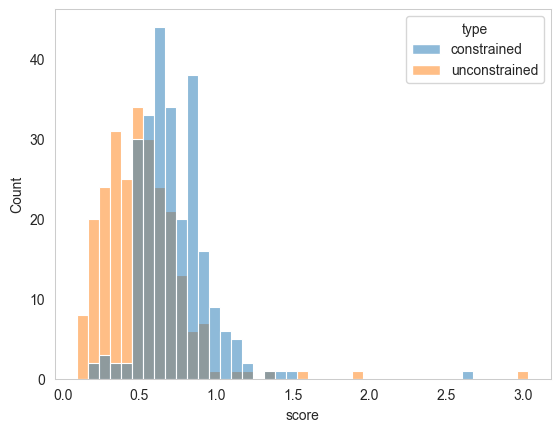

In [104]:
plt.figure()
sns.histplot(data = df, x = 'score',hue = 'type')